# 00 · Where the evidence comes from

**Reader goal:** understand who and what the experiment covers, what was filtered,
and the difference between raw reports, extracted metrics, evidence cards and
what the generator actually saw.

**Reading route:** selection → geography and sectors → coverage → evidence scale
→ time boundaries → a traceable source-to-prompt example.

This is a retrospective data description. The country field comes from the
company register; it is not a map of offices, operations or environmental impacts.

**How to read this notebook.** Each figure begins with a specific question. Its
caption explains the encodings and analysis scope; the following paragraphs
describe the observed pattern, its interpretation, and the remaining limits.
For multi-panel figures, read the individual panels and then their joint meaning.
“Middle half” means the 25th–75th percentiles. In an empirical cumulative
distribution (ECDF), the vertical coordinate is the proportion at or below the
horizontal value; a steep section marks a concentration of observations.
All of this text remains visible when code is hidden.

In [1]:
from pathlib import Path
import sys
analysis_dir = Path.cwd()
if not (analysis_dir / 'analysis_data.py').exists():
    analysis_dir = analysis_dir / 'BACE' / 'analysis'
assert (analysis_dir / 'analysis_data.py').exists(), 'Run from the project root or analysis directory.'
sys.path.insert(0, str(analysis_dir))
sys.dont_write_bytecode = True
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from analysis_data import (load_snapshot, company_bootstrap, case_material, read, rows,
                           save_json, sha, HERE, BACE, ROOT, OUT, CACHE, SEED, METHODS, TASKS, LABELS)
from figure_style import (canvas, save_figure, quote_figure, ecdf, note,
                          BLUE, GREEN, ORANGE, GREY, INK, CMAP,
                          METHOD_COLORS, TYPE_COLORS, LABEL_NAMES, LABEL_COLORS)
tables = load_snapshot()
metrics = tables['metrics']
common = metrics.loc[metrics.bace_complete & metrics.ragchecker_complete & metrics.ragas_complete].copy()
bace = metrics.loc[metrics.bace_complete].copy()
claims = tables['claims']
sample = read(CACHE / 'sample.json')
execution = read(CACHE / 'execution.json')
note(f"**Snapshot:** {len(metrics):,} planned disclosures from {metrics.company_id.nunique()} companies; "
     f"{len(bace):,} complete BACE results and {len(common):,} common completed cases. "
     f"Run status: `{execution['status']}`. All results are automated; no human accuracy benchmark is supplied.")

**Snapshot:** 1,800 planned disclosures from 30 companies; 1,798 complete BACE results and 1,798 common completed cases. Run status: `incomplete`. All results are automated; no human accuracy benchmark is supplied.

## 1. How did the source register become the experimental sample?

The frozen eligibility rule requires a known SICS sector, at least one valid
nonempty CSV metric in every year 2015–2023, and a PDF with a valid header in every
year 2015–2022. Parsing is checked subsequently. Selection did not use evaluator
scores. One company is allocated to each eligible sector; the remaining places
use the frozen proportional allocation rule.

<a id="reading-00_selection"></a>

**Figure question · 00 selection.** How much of the source register survives availability screening and final selection?

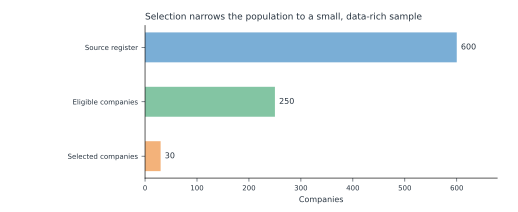

**Read the figure:** bar lengths are company counts, not disclosures. No uncertainty interval applies to these census counts. **Boundary:** eligibility guarantees minimum source availability, not task completeness or extraction accuracy.

[PDF](outputs/figures/00/00_selection.pdf) · [SVG](outputs/figures/00/00_selection.svg) · [PNG](outputs/figures/00/00_selection.png) · [Source data: data](outputs/figures/00/00_selection__data.csv)

**Pattern and evidence.** The bars contract from 600 to 250 to 30 companies: 41.7% are eligible, and 12.0% of that eligible pool is selected (5.0% of the register). Most of the initial reduction therefore happens before sampling.

**Interpretation.** Subsequent results describe a small subset with sustained historical source availability. The sharp narrowing makes the selection rule part of the interpretation of every later score.

**Limits and alternative readings.** These are exact counts for this register, without sampling-error bars. Availability screening does not establish report quality, accurate extraction, or representativeness of the wider company population.

In [2]:
selection = tables['selection']
stages = pd.DataFrame({'stage':['Source register','Eligible companies','Selected companies'],
                       'companies':[len(selection), int(selection.eligible.sum()), int(selection.selected.sum())]})
fig, (ax,) = canvas(height=75,left=.28)
ax.barh(stages.stage, stages.companies, color=[BLUE,GREEN,ORANGE],height=.55)
ax.invert_yaxis(); ax.set_xlabel('Companies'); ax.set_xlim(0, stages.companies.max()*1.13)
for i,n in enumerate(stages.companies): ax.text(n+8,i,str(n),va='center',fontsize=8)
ax.set_title('Selection narrows the population to a small, data-rich sample',loc='left')
save_figure(fig,'00_selection',stages,
    '**Read the figure:** bar lengths are company counts, not disclosures. No uncertainty interval applies to these census counts. '
    '**Boundary:** eligibility guarantees minimum source availability, not task completeness or extraction accuracy.')

## 2. Which places and sectors does the sample cover?

The map locates countries recorded for the selected companies. The sector plot
compares proportions at all three selection stages, so a small sector is not
mistaken for a large one merely because every sector receives at least one place.

<a id="reading-00_geography"></a>

**Figure question · 00 geography.** After selection, where are the companies registered, and is geographical coverage evenly spread?

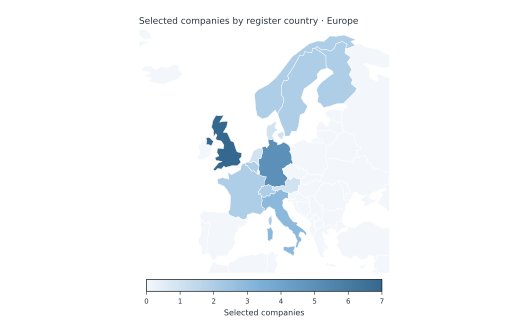

**Read the figure:** colour encodes selected company counts; zero means no selected company. All selected register countries lie in the displayed European extent. Natural Earth v5.1.2, public domain; cylindrical longitude/latitude display with aspect adjusted at 53°N. **Boundary:** this is register geography, not operational exposure; boundaries are contextual.

[PDF](outputs/figures/00/00_geography.pdf) · [SVG](outputs/figures/00/00_geography.svg) · [PNG](outputs/figures/00/00_geography.png) · [Source data: data](outputs/figures/00/00_geography__data.csv)

**Pattern and evidence.** The map covers 12 European register countries. The darkest countries are United Kingdom (7) and Germany (5); together they account for 12/30 companies (40.0%). 3 countries contribute only one company each. The concentration is in selected company counts, not in country land area.

**Interpretation.** This uneven coverage identifies where the sample has more observations and where a country-specific reading would depend on a single company. The country field locates the register entry; multinational operations can extend far beyond it.

**Limits and alternative readings.** Colour represents counts, not companies per capita, market share or environmental impact. Large polygons draw more visual attention without receiving greater statistical weight. Uncoloured countries have no selected companies; they do not have zero ESG activity.

In [3]:
from matplotlib.patches import Polygon
from matplotlib.collections import PatchCollection
from matplotlib.colors import Normalize
from shapely.geometry import shape, box
countries = selection.loc[selection.selected].groupby('country').size().rename('companies').reset_index()
geo = read(HERE/'assets/ne_110m_admin_0_countries.geojson')
provenance = read(HERE/'assets/basemap_source.json')
assert sha(HERE/'assets/ne_110m_admin_0_countries.geojson') == provenance['sha256']
counts = countries.set_index('country').companies.to_dict()
fig, (ax,) = canvas(height=117,left=.06,right=.96,bottom=.12,top=.91)
patches, values, matched = [], [], set()
for feature in geo['features']:
    name = feature['properties']['ADMIN']
    if name in counts: matched.add(name)
    geometry = shape(feature['geometry']).intersection(box(-25,34,40,72))
    if geometry.is_empty: continue
    polys = list(geometry.geoms) if geometry.geom_type=='MultiPolygon' else [geometry]
    for poly in polys:
        if poly.geom_type=='Polygon':
            patches.append(Polygon(np.array(poly.exterior.coords))); values.append(counts.get(name,0))
assert matched == set(counts), f'Unmapped register countries: {set(counts)-matched}'
collection = PatchCollection(patches,cmap=CMAP,norm=Normalize(0,max(counts.values())),edgecolor='white',linewidth=.4)
collection.set_array(np.array(values)); ax.add_collection(collection)
ax.set_xlim(-25,40);ax.set_ylim(34,72);ax.set_aspect(1/np.cos(np.deg2rad(53)))
ax.axis('off'); ax.set_title('Selected companies by register country · Europe',loc='left')
cb=fig.colorbar(collection,ax=ax,orientation='horizontal',fraction=.045,pad=.025,shrink=.65)
cb.set_label('Selected companies');cb.set_ticks(range(0,max(counts.values())+1))
save_figure(fig,'00_geography',countries,
    '**Read the figure:** colour encodes selected company counts; zero means no selected company. All selected register countries lie in the displayed European extent. '
    'Natural Earth v5.1.2, public domain; cylindrical longitude/latitude display with aspect adjusted at 53°N. '
    '**Boundary:** this is register geography, not operational exposure; boundaries are contextual.')

<a id="reading-00_sector_selection"></a>

**Figure question · 00 sector selection.** Does the geographical sample also preserve the sector mix, or does stratification change it?

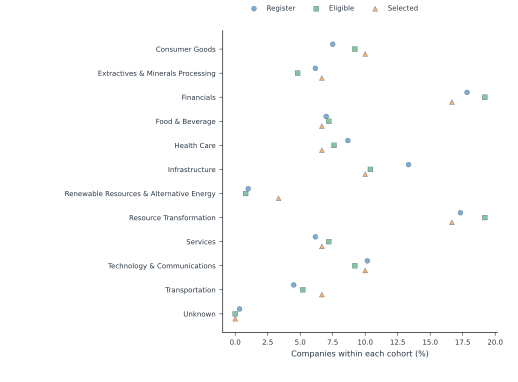

**Read the figure:** points show sector shares within each cohort; marker shape also distinguishes cohorts. All sectors, including missing classification, are retained. **Boundary:** stratification preserves sector coverage, not the original sector proportions; small selected sectors cannot support stable sector-specific inference.

[PDF](outputs/figures/00/00_sector_selection.pdf) · [SVG](outputs/figures/00/00_sector_selection.svg) · [PNG](outputs/figures/00/00_sector_selection.png) · [Source data: data](outputs/figures/00/00_sector_selection__data.csv)

**Pattern and evidence.** The selected markers cover 11 sectors. Financials (5/30; 16.7%) and Resource Transformation (5/30; 16.7%) are the largest groups. Renewable Resources & Alternative Energy rises from 0.8% of eligible companies to 3.3% of selected companies, but still contains only 1 company. Selected-minus-eligible shifts span -2.5 to +2.5 percentage points.

**Interpretation.** The minimum allocation of one company per eligible sector raises the relative weight of a small sector and reduces that of larger sectors. Marker separation is therefore an expected consequence of allocation, not evidence that some sectors perform better.

**Limits and alternative readings.** Each cohort has its own denominator (600, 250 or 30). A selected share of 3.3% is one company; its many repeated disclosures cannot substitute for multiple independent companies in that sector.

In [4]:
sector_rows=[]
for label, subset in [('Register',selection),('Eligible',selection[selection.eligible]),('Selected',selection[selection.selected])]:
    for sector,n in subset.groupby('primary_sics_sector',dropna=False).size().items():
        sector_rows.append({'cohort':label,'sector':sector if pd.notna(sector) else 'Unknown','companies':n,'denominator':len(subset),'percent':100*n/len(subset)})
sector_data=pd.DataFrame(sector_rows)
sector_order=sorted(sector_data.sector.unique())
fig,(ax,)=canvas(height=135,left=.43,top=.92,bottom=.13)
for j,(group,color,marker) in enumerate(zip(['Register','Eligible','Selected'],[BLUE,GREEN,ORANGE],['o','s','^'])):
    view=sector_data[sector_data.cohort==group].set_index('sector').reindex(sector_order).fillna(0)
    ax.scatter(view.percent,np.arange(len(view))+(j-1)*.20,color=color,marker=marker,s=24,label=group,edgecolor=INK,linewidth=.25)
ax.set_yticks(range(len(sector_order)),sector_order);ax.invert_yaxis();ax.set_xlabel('Companies within each cohort (%)')
ax.legend(loc='lower center',bbox_to_anchor=(.4,1.04),ncols=3)
save_figure(fig,'00_sector_selection',sector_data,
    '**Read the figure:** points show sector shares within each cohort; marker shape also distinguishes cohorts. All sectors, including missing classification, are retained. '
    '**Boundary:** stratification preserves sector coverage, not the original sector proportions; small selected sectors cannot support stable sector-specific inference.')

## 3. What coverage is available, and what does eligibility hide?

A nonzero source count is only an availability signal. It does not prove that a
report discusses a particular ESRS task. PDF counts below refer to valid headers
recorded during screening; canonical cards later reflect parsing and quarantine.

<a id="reading-00_source_coverage"></a>

**Figure question · 00 source coverage.** Within the selected sample, does complete annual availability also mean equal amounts of source material?

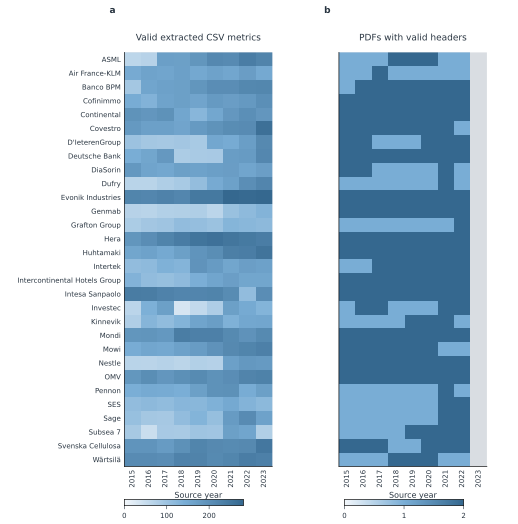

**Read the figure:** rows are the same 30 companies; columns are source years. Each panel has its own count scale. Grey in the PDF 2023 column is outside the required source window, not observed absence. **Boundary:** minimum annual coverage is selected by design; metric completeness and task relevance remain uneven.

[PDF](outputs/figures/00/00_source_coverage.pdf) · [SVG](outputs/figures/00/00_source_coverage.svg) · [PNG](outputs/figures/00/00_source_coverage.png) · [Source data: data](outputs/figures/00/00_source_coverage__data.csv)

**Pattern and evidence.** Panel a has no empty required company-year cells, but CSV counts range from 33 to 281 (median 167; middle half 123–205). The across-company median increases from 140.5 in 2015 to 203.0 in 2023. Row averages also differ: Genmab has 86.9 metrics versus Evonik Industries with 246.3. Panel b is much more discrete: 79 of 240 required cells have one PDF and 161 have two; 30 grey cells are outside the PDF window.

**Interpretation.** Together, the panels separate a binary entry requirement from uneven evidence volume. The CSV columns become richer in later years at the sample-median level, while the PDF view mostly distinguishes one versus two reports. These features can change what is available for retrieval even though every selected company passes screening.

**Limits and alternative readings.** The two colour scales have different units and ranges: equally dark cells do not contain equal evidence. More extracted metrics could reflect reporting, extraction coverage or both; it does not establish improving ESG performance. The annual pattern is descriptive for selected companies, not an independent time-series experiment.

<a id="reading-00_screening_gaps"></a>

**Figure question · 00 screening gaps.** The selected heatmaps hide excluded companies; which availability gaps dominate the full register?

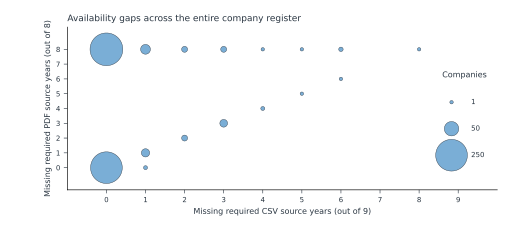

**Read the figure:** each point groups companies with the same two gap counts; marker area is 4 × company count + 8 points². All 600 screening records are included. No interval is shown for observed counts. Sector classification is an additional eligibility condition.

[PDF](outputs/figures/00/00_screening_gaps.pdf) · [SVG](outputs/figures/00/00_screening_gaps.svg) · [PNG](outputs/figures/00/00_screening_gaps.png) · [Source data: data](outputs/figures/00/00_screening_gaps__data.csv)

**Pattern and evidence.** Two bubbles dominate: 250 companies at (0, 0), and 267 at (0, 8). The latter have all nine required CSV years but no qualifying PDF year. Together these two locations contain 86.2% of the register. At least one CSV year is missing for 83 companies and at least one PDF year for 348; these groups overlap.

**Interpretation.** The large vertical separation at zero missing CSV years shows that PDF availability is a major screening constraint. The smaller points elsewhere describe joint gaps rather than a smooth continuum of equally populated coverage levels.

**Limits and alternative readings.** A missing qualifying PDF is a gap in this collected and screened corpus, not proof that the company published no report. Bubble area has a small visibility offset, so count ratios should be read from the source table, not inferred precisely from diameter. Known sector classification is an additional eligibility condition.

In [5]:
coverage=tables['coverage']; selected_coverage=coverage[coverage.selected]
company_order=sorted(selected_coverage.company_name.unique())
fig,axs=canvas(height=185,cols=2,left=.24,right=.94,bottom=.11,top=.90,wspace=.45)
for ax,column,title in zip(axs,['csv_valid_metrics','pdf_valid_headers'],['Valid extracted CSV metrics','PDFs with valid headers']):
    grid=selected_coverage.pivot(index='company_name',columns='year',values=column).reindex(company_order)
    image=ax.imshow(np.ma.masked_invalid(grid.to_numpy()),aspect='auto',cmap=CMAP,vmin=0,interpolation='none')
    ax.set_facecolor('#D9DDE2');ax.set_xticks(range(len(grid.columns)),grid.columns,rotation=90)
    ax.set_yticks(range(len(grid)),grid.index if ax is axs[0] else ['']*len(grid));ax.tick_params(axis='both',length=0)
    ax.set_title(title,pad=12);ax.set_xlabel('Source year')
    # A shared figure-level horizontal strip avoids shrinking either comparison panel.
    cbax=fig.add_axes([.24 if ax is axs[0] else .665,.035,.23,.012]);cbax.set_label('<colorbar>')
    cbar=fig.colorbar(image,cax=cbax,orientation='horizontal')
    if column=='pdf_valid_headers': cbar.set_ticks([0,1,2])
save_figure(fig,'00_source_coverage',selected_coverage,
    '**Read the figure:** rows are the same 30 companies; columns are source years. Each panel has its own count scale. '
    'Grey in the PDF 2023 column is outside the required source window, not observed absence. '
    '**Boundary:** minimum annual coverage is selected by design; metric completeness and task relevance remain uneven.',axes=list(axs))
missing=selection.groupby(['missing_csv_year_count','missing_pdf_year_count'],dropna=False).size().reset_index(name='companies')
fig,(ax,)=canvas(height=80)
ax.scatter(missing.missing_csv_year_count,missing.missing_pdf_year_count,s=missing.companies*4+8,color=BLUE,edgecolor=INK,linewidth=.4)
ax.set_xlabel('Missing required CSV source years (out of 9)');ax.set_ylabel('Missing required PDF source years (out of 8)')
for n in [1,50,250]: ax.scatter([],[],s=n*4+8,color=BLUE,edgecolor=INK,linewidth=.4,label=str(n))
ax.legend(title='Companies',loc='center right',bbox_to_anchor=(1,.46),labelspacing=2.8,borderpad=1,handletextpad=1.8)
ax.set_xticks(range(10));ax.set_yticks(range(9));ax.set_xlim(-1,10);ax.set_ylim(-1.5,9.5);ax.set_title('Availability gaps across the entire company register',loc='left')
save_figure(fig,'00_screening_gaps',missing,
    '**Read the figure:** each point groups companies with the same two gap counts; marker area is 4 × company count + 8 points². '
    'All 600 screening records are included. No interval is shown for observed counts. Sector classification is an additional eligibility condition.')

## 4. How much evidence exists, and how much reaches a prompt?

Canonical cards are derived representations. One report may produce many cards;
a card can appear in several overlapping year packages and in several prompts.
These levels must not be added together or interpreted as independent evidence.

<a id="reading-00_evidence_scale"></a>

**Figure question · 00 evidence scale.** How unequal are the sizes and text lengths of the three stored evidence representations?

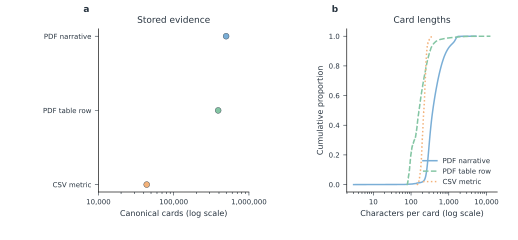

**Read the figure:** panel a counts unique canonical cards by representation; panel b is the exact empirical cumulative distribution of retrieval-text lengths, weighted by the observed frequency of each length. No cards are sampled or dropped. Long cards contribute one observation each, not extra evidence units.

[PDF](outputs/figures/00/00_evidence_scale.pdf) · [SVG](outputs/figures/00/00_evidence_scale.svg) · [PNG](outputs/figures/00/00_evidence_scale.png) · [Source data: counts](outputs/figures/00/00_evidence_scale__counts.csv) · [Source data: length_frequencies](outputs/figures/00/00_evidence_scale__length_frequencies.csv)

**Pattern and evidence.** Panel a contains PDF narrative: 497,551 cards (53.4%); PDF table row: 390,070 cards (41.9%); CSV metric: 43,827 cards (4.7%). PDF-derived cards dominate stored volume. In panel b, the steep part of each ECDF marks a densely populated length range: PDF narrative: median 377, middle half 298–564, 99th percentile 1,602, maximum 5,300 characters; PDF table row: median 163, middle half 106–233, 99th percentile 1,122, maximum 12,745 characters; CSV metric: median 219, middle half 195–242, 99th percentile 317, maximum 390 characters. CSV cards occupy a narrow band; narrative cards are typically longer. Table rows have a short median but a long sparse upper tail, so their maximum does not describe a typical row.

**Interpretation.** The panels jointly distinguish how many units exist from how much text each unit contains. A type can be numerous without having the longest individual records, and text length affects the size of the material retrieval must handle.

**Limits and alternative readings.** Both horizontal axes are logarithmic: equal spacing means a multiplicative change, not an equal count or character increment. Long extracted rows may reflect complex tables or extraction artefacts; length alone cannot diagnose either. Cards are representations that may share a source report, not independent factual observations.

<a id="reading-00_visible_evidence"></a>

**Figure question · 00 visible evidence.** How does the large canonical library translate into the much smaller evidence context seen by each generator call?

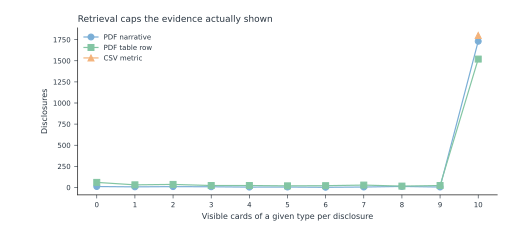

**Read the figure:** frequencies cover all planned disclosures, including zero-card strata. Retrieval selects up to 10 cards of each type using BM25/dense retrieval and reciprocal-rank fusion; unused slots are not redistributed. **Boundary:** the generator sees these selected cards, not the entire canonical library or source reports.

[PDF](outputs/figures/00/00_visible_evidence.pdf) · [SVG](outputs/figures/00/00_visible_evidence.svg) · [PNG](outputs/figures/00/00_visible_evidence.png) · [Source data: data](outputs/figures/00/00_visible_evidence__data.csv)

**Pattern and evidence.** All three series peak at the cap of ten cards: PDF narrative: 1,731/1,800 disclosures (96.2%); PDF table row: 1,520/1,800 disclosures (84.4%); CSV metric: 1,800/1,800 disclosures (100.0%). Zero-card strata occur for 11 narrative and 60 table-row contexts. Total visible cards range from 10 to 30, with median 30.

**Interpretation.** The peak is a retrieval-design ceiling. CSV reaches it for every disclosure, while PDF strata sometimes fall short. Consequently, representation balance at the prompt is very different from the proportions in canonical storage.

**Limits and alternative readings.** Connecting lines join frequencies at discrete counts; they are not a time trend or a continuous density. Unused slots are not reassigned to other types. Hitting the cap says nothing about topical relevance, and failing to fill it does not establish that relevant material is absent from all original reports.

**Observed:** 931,448 canonical cards feed 150 overlapping company-year packages. There are 51,806 visible card appearances, representing 19,668 distinct retrieved cards across 1,800 prompts.

In [6]:
canonical=tables['canonical_counts'];lengths=tables['length_counts'];visible=tables['visible']
fig,axs=canvas(height=85,cols=2,left=.19,right=.96,bottom=.20,top=.88,wspace=.65)
counts=canonical.groupby('type').cards.sum().reindex(TYPE_COLORS)
assert (counts>0).all() and (lengths.characters>0).all(), 'Logarithmic views require positive observed values.'
axs[0].scatter(counts.values,counts.index,color=list(TYPE_COLORS.values()),s=35,edgecolor=INK,linewidth=.4);axs[0].invert_yaxis()
axs[0].set_xscale('log');axs[0].set_xlim(1e4,1e6);axs[0].set_xticks([1e4,1e5,1e6],['10,000','100,000','1,000,000']);axs[0].set_xlabel('Canonical cards (log scale)');axs[0].set_title('Stored evidence')
for typ,color in TYPE_COLORS.items():
    view=lengths[lengths.type==typ].sort_values('characters')
    axs[1].step(view.characters,view['count'].cumsum()/view['count'].sum(),where='post',color=color,label=typ,ls={'PDF narrative':'-','PDF table row':'--','CSV metric':':'}[typ])
axs[1].set_xscale('log');axs[1].set_xticks([10,100,1000,10000],['10','100','1,000','10,000']);axs[1].set_xlabel('Characters per card (log scale)');axs[1].set_ylabel('Cumulative proportion')
from matplotlib.ticker import NullFormatter
for axis in axs: axis.xaxis.set_minor_formatter(NullFormatter())
axs[1].set_title('Card lengths');axs[1].legend(loc='lower right')
save_figure(fig,'00_evidence_scale',{'counts':counts.rename('cards').reset_index(),'length_frequencies':lengths},
    '**Read the figure:** panel a counts unique canonical cards by representation; panel b is the exact empirical cumulative distribution of retrieval-text lengths, weighted by the observed frequency of each length. '
    'No cards are sampled or dropped. Long cards contribute one observation each, not extra evidence units.')
prompt_counts=visible.groupby(['generation_case_id','type']).size().unstack(fill_value=0).reindex(metrics.generation_case_id,fill_value=0).reindex(columns=TYPE_COLORS,fill_value=0)
fig,(ax,)=canvas(height=82,left=.15)
for typ,color in TYPE_COLORS.items():
    frequency=prompt_counts[typ].value_counts().sort_index()
    ax.plot(frequency.index,frequency.values,marker={'PDF narrative':'o','PDF table row':'s','CSV metric':'^'}[typ],color=color,label=typ,lw=1.2)
ax.set_xlabel('Visible cards of a given type per disclosure');ax.set_ylabel('Disclosures');ax.legend(loc='upper left')
ax.set_xticks(range(11));ax.set_title('Retrieval caps the evidence actually shown',loc='left')
save_figure(fig,'00_visible_evidence',prompt_counts.reset_index(),
    '**Read the figure:** frequencies cover all planned disclosures, including zero-card strata. Retrieval selects up to 10 cards of each type using BM25/dense retrieval and reciprocal-rank fusion; unused slots are not redistributed. '
    '**Boundary:** the generator sees these selected cards, not the entire canonical library or source reports.')
note(f"**Observed:** {int(counts.sum()):,} canonical cards feed {len(tables['packages'][['company_id','year']].drop_duplicates())} overlapping company-year packages. "
     f"There are {len(visible):,} visible card appearances, representing {visible.evidence_id.nunique():,} distinct retrieved cards across {len(metrics):,} prompts.")

## 5. Which source years can inform a target-year disclosure?

For target year *t*, CSV evidence uses *t−4…t* and PDF evidence uses *t−4…t−1*.
These are report-year rules, not a historical publication-date cutoff. The use of
2023-edition ESRS task wording for earlier target years is an experimental task
framing, not evidence that those disclosures were legally required then.

<a id="reading-00_time_windows"></a>

**Figure question · 00 time windows.** Which temporal boundary governs the evidence just counted, and how much do neighbouring target years share?

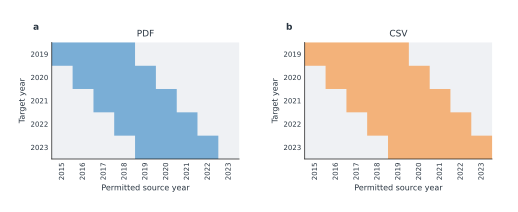

**Read the figure:** coloured cells are allowed report years, grey cells are excluded by the protocol. This is the configured eligibility window, not a count of available records or proof of publication availability.

[PDF](outputs/figures/00/00_time_windows.pdf) · [SVG](outputs/figures/00/00_time_windows.svg) · [PNG](outputs/figures/00/00_time_windows.png) · [Source data: data](outputs/figures/00/00_time_windows__data.csv)

**Pattern and evidence.** Both panels form diagonal bands that move one column right with each target year. Panel a permits four PDF report years per target and ends one year before it; panel b permits five CSV years and includes the target year. For 2019 these are 2015–2018 and 2015–2019; for 2023 they are 2019–2022 and 2019–2023.

**Interpretation.** The one-column difference explains why target-year numerical metrics may be available alongside older narrative descriptions. Adjacent target years share three permitted PDF years and four CSV years, so their source pools overlap substantially. Later changes in scores therefore occur within moving, overlapping windows.

**Limits and alternative readings.** These cells encode a rule, not observed availability, score magnitude or publication dates. The band shape is imposed by design and is not an empirical trend. It cannot establish what a user could have known at a historical date.

In [7]:
time_rows=[]
for target in sorted(metrics.year.unique()):
    for typ,lag in [('PDF',1),('CSV',0)]:
        for source in range(2015,2024):
            time_rows.append({'target_year':target,'type':typ,'source_year':source,'included':int(target-4<=source<=target-lag)})
time_data=pd.DataFrame(time_rows)
fig,axs=canvas(height=75,cols=2,left=.10,right=.95,bottom=.25,top=.80,wspace=.35)
from matplotlib.colors import ListedColormap
for ax,typ,color in zip(axs,['PDF','CSV'],[BLUE,ORANGE]):
    grid=time_data[time_data.type==typ].pivot(index='target_year',columns='source_year',values='included')
    ax.imshow(grid,aspect='auto',cmap=ListedColormap(['#EFF1F4',color]),vmin=0,vmax=1)
    ax.set_xticks(range(9),range(2015,2024),rotation=90);ax.set_yticks(range(5),grid.index)
    ax.set_xlabel('Permitted source year');ax.set_ylabel('Target year');ax.set_title(typ);ax.tick_params(length=0)
save_figure(fig,'00_time_windows',time_data,
    '**Read the figure:** coloured cells are allowed report years, grey cells are excluded by the protocol. This is the configured eligibility window, not a count of available records or proof of publication availability.')

## 6. Can a reader trace a prompt card back to a source?

The following deterministic example uses the first frozen case and the first
visible PDF narrative card. It illustrates the data path; it is not selected for
support success. The complete case evidence is exported alongside the figure.

<a id="reading-00_provenance_example"></a>

**Figure question · 00 provenance example.** What survives the transformation from an original report into one specific prompt input?

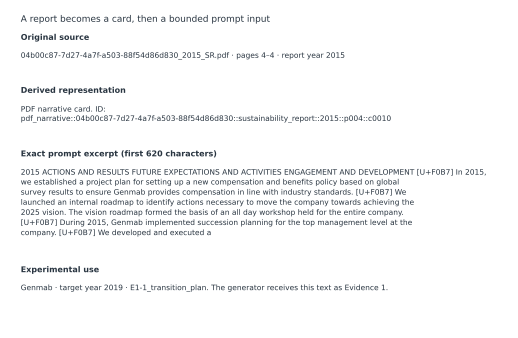

**Read the figure:** the excerpt is copied verbatim from the frozen visible card and checked against the canonical index. Source filename and page references identify the underlying report. **Boundary:** a PDF-to-card transformation can lose layout or extraction detail; CSV values are also extracted outputs, not unquestioned ground truth. **Display note:** unsupported source glyphs are shown as Unicode code-point escapes (U+F0B7); the exact original text remains in the source table and case bundle.

[PDF](outputs/figures/00/00_provenance_example.pdf) · [SVG](outputs/figures/00/00_provenance_example.svg) · [PNG](outputs/figures/00/00_provenance_example.png) · [Source data: data](outputs/figures/00/00_provenance_example__data.csv)

**Pattern and evidence.** Read downward through four stages: the 2015 sustainability report and page 4, the narrative-card identifier, the first 620 characters of the frozen card, and its use as Evidence 1 for Genmab’s 2019 E1-1 task. The displayed text concerns compensation, employee development and an internal roadmap; it does not itself provide an explicit climate-transition-plan statement. The excerpt boundary also cuts off the final sentence.

**Interpretation.** The identifiers make the representation traceable, while the content shows why provenance and relevance are separate questions. An exact card-to-prompt match confirms which extracted text was shown; it does not establish that the card answers the target task.

**Limits and alternative readings.** This is the first case and first visible narrative card, not a representative random relevance audit. The displayed excerpt is truncated; no claim about the entire card or report follows from that truncation. Matching extracted text cannot verify the preservation of the original PDF layout.

In [8]:
first_id=read(BACE/'results/main_v1/manifest.json')['case_ids'][0]
example=case_material(first_id)
card=next(c for c in example['input']['prompt_evidence'] if c['shown_in_prompt'] and c['evidence_type']=='narrative')
canonical_card=next(c for c in read(CACHE/'canonical_examples.json') if c['evidence_id']==card['evidence_id'])
assert canonical_card['retrieval_text']==card['retrieval_text']
example_dir=OUT/'examples';example_dir.mkdir(exist_ok=True)
save_json(example_dir/'00_source_to_prompt.json',{'case':example['input'],'canonical_card':canonical_card})
excerpt=card['retrieval_text'][:620]
blocks=[('Original source',f"{card['source_file']} · pages {card['page_start']}–{card['page_end']} · report year {card['source_year']}"),
        ('Derived representation',f"PDF narrative card. ID: {card['evidence_id']}"),
        ('Exact prompt excerpt'+(' (first 620 characters)' if len(card['retrieval_text'])>620 else ''),excerpt),
        ('Experimental use',f"{example['input']['company_name']} · target year {example['input']['target_reporting_year']} · {example['input']['task_id']}. The generator receives this text as {card['prompt_label']}.")]
quote_figure('00_provenance_example','A report becomes a card, then a bounded prompt input',blocks,
    pd.DataFrame([{'stage':a,'text':b} for a,b in blocks]),
    '**Read the figure:** the excerpt is copied verbatim from the frozen visible card and checked against the canonical index. Source filename and page references identify the underlying report. '
    '**Boundary:** a PDF-to-card transformation can lose layout or extraction detail; CSV values are also extracted outputs, not unquestioned ground truth.')

## What the reader should now be able to explain

- The sample is stratified and availability-filtered; it is not the entire register.
- Country and sector coverage constrain generalisation.
- Raw reports, extracted CSV metrics, canonical cards, overlapping packages and prompt-visible evidence are distinct objects.
- Complete annual availability does not imply complete task evidence.
- The next notebook assesses generated disclosures **within the visible evidence boundary**.

## Reproducibility and interpretation boundary

Each figure is exported to `outputs/figures/` as editable PDF/SVG and 600 dpi PNG,
with its plotted source table(s), caption, and rendered QA records. The snapshot
manifest records source hashes and the verification scope. All observations are
retained unless an explicitly named cohort or case-selection rule is stated.

The source checks cover consumed artifacts and their completed-stage receipts,
shared prompt/context/response identity, and native metric arithmetic. They are
not a new audit of every raw model call or the entire extraction lineage.
Read the final audit report for figure-level visual checks and any reviewed warnings.